# DQN and PPO Model Comparison

In this notebook, we compare DQN model with PPO model. We test both models on the same 100 new episode seeds and always select the action with the highest score.

## 1. Setup

import the libraries, select the two model files, and create one seed list for both agents.

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

from model import load_model

DQN_CHECKPOINT = "dqn_lunar_lander.pt"
PPO_CHECKPOINT = "PPO/ppo_lunar_lander_stable_finetuned_best.pt"
SEEDS = list(range(50_000, 50_100))

torch.set_num_threads(1)
print("Evaluation episodes:", len(SEEDS))
print("First and last seeds:", SEEDS[0], SEEDS[-1])

Evaluation episodes: 100
First and last seeds: 50000 50099


## 2. Load the saved models

 load the saved weights and check that both models return four action scores.

In [2]:
dqn_model = load_model("dqn", DQN_CHECKPOINT)
ppo_model = load_model("ppo", PPO_CHECKPOINT)

example_state = torch.zeros(8, dtype=torch.float32)
with torch.no_grad():
    dqn_scores = dqn_model(example_state)
    ppo_scores, _ = ppo_model(example_state)

assert dqn_scores.shape == (4,)
assert ppo_scores.shape == (4,)
print("Both checkpoints loaded correctly")

Both checkpoints loaded correctly


## 3. Shared evaluation function

use the same function for both models. For each seed, it runs one full episode and selects the action with the highest score.

In [3]:
def evaluate_model(model, algorithm, seeds):
    environment = gym.make("LunarLander-v3", render_mode=None)
    rewards = []
    lengths = []

    try:
        for seed in seeds:
            state, info = environment.reset(seed=seed)
            total_reward = 0.0
            steps = 0
            finished = False

            while not finished:
                state_tensor = torch.as_tensor(state, dtype=torch.float32)

                with torch.no_grad():
                    action_scores = model(state_tensor)
                    if algorithm == "ppo":
                        action_scores = action_scores[0]
                    action = torch.argmax(action_scores).item()

                state, reward, terminated, truncated, info = environment.step(action)
                total_reward += reward
                steps += 1
                finished = terminated or truncated

            rewards.append(float(total_reward))
            lengths.append(steps)
    finally:
        environment.close()

    return {"seeds": list(seeds), "rewards": rewards, "lengths": lengths}

## 4. Run both agents

run 100 complete episodes for DQN and 100 for PPO.

In [4]:
dqn_results = evaluate_model(dqn_model, "dqn", SEEDS)
ppo_results = evaluate_model(ppo_model, "ppo", SEEDS)

print("DQN episodes:", len(dqn_results["rewards"]))
print("PPO episodes:", len(ppo_results["rewards"]))

DQN episodes: 100
PPO episodes: 100


## 5. Metrics

calculate the mean, standard deviation, median, minimum, maximum, and the number of episodes with a reward of at least 200.

In [5]:
def calculate_metrics(rewards):
    values = np.asarray(rewards, dtype=np.float64)
    return {
        "mean": float(values.mean()),
        "std": float(values.std()),
        "median": float(np.median(values)),
        "minimum": float(values.min()),
        "maximum": float(values.max()),
        "episodes_above_200": int(np.sum(values >= 200)),
    }

comparison_metrics = {
    "DQN": calculate_metrics(dqn_results["rewards"]),
    "PPO": calculate_metrics(ppo_results["rewards"]),
}

comparison_metrics

{'DQN': {'mean': 249.44757722224094,
  'std': 54.40958055080499,
  'median': 263.0272113514959,
  'minimum': 14.004159842474891,
  'maximum': 318.42119842024954,
  'episodes_above_200': 87},
 'PPO': {'mean': 230.05931903307533,
  'std': 67.76599595094268,
  'median': 250.56496771846614,
  'minimum': -30.567866033083135,
  'maximum': 292.4692349354775,
  'episodes_above_200': 84}}

In [6]:
print(f"{'Model':<8} {'Mean':>9} {'Std':>9} {'Median':>9} {'Min':>9} {'Max':>9} {'>= 200':>8}")
for name in ["DQN", "PPO"]:
    metrics = comparison_metrics[name]
    print(
        f"{name:<8} {metrics['mean']:>9.2f} {metrics['std']:>9.2f} "
        f"{metrics['median']:>9.2f} {metrics['minimum']:>9.2f} "
        f"{metrics['maximum']:>9.2f} {metrics['episodes_above_200']:>8}"
    )

Model         Mean       Std    Median       Min       Max   >= 200
DQN         249.45     54.41    263.03     14.00    318.42       87
PPO         230.06     67.77    250.56    -30.57    292.47       84


## 6. Graphs

three simple graphs: rewards by episode, reward distributions, and a boxplot.

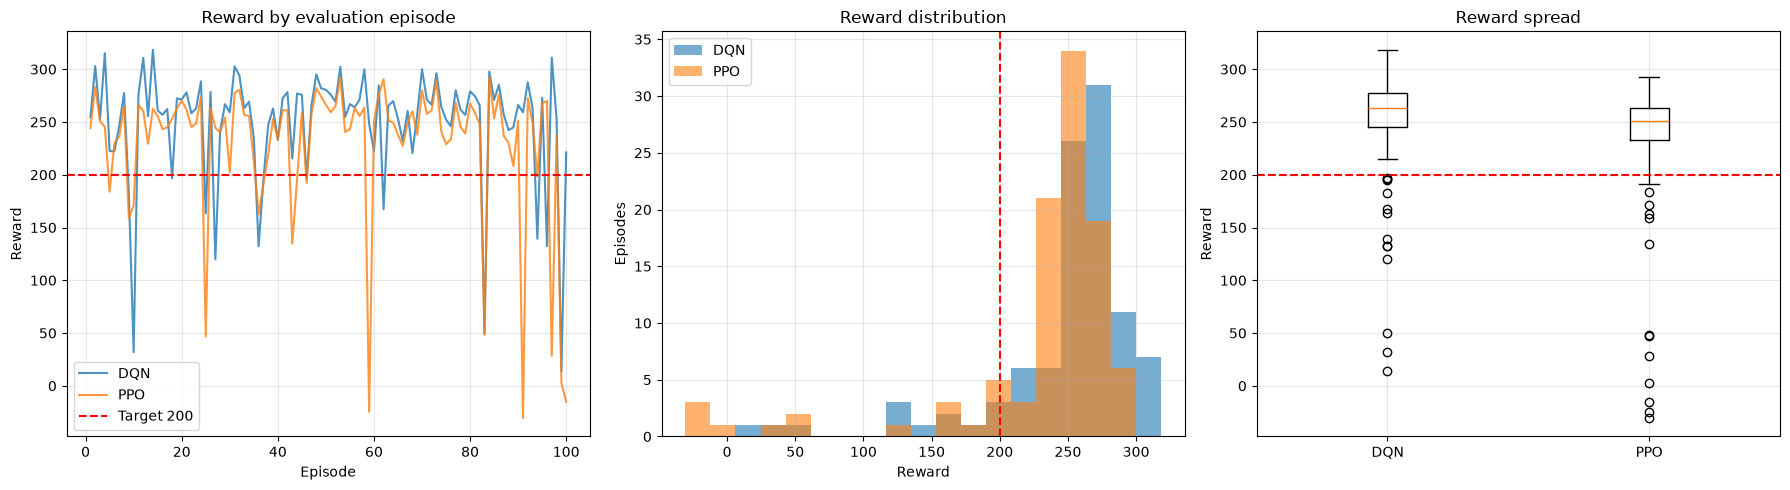

In [7]:
episodes = np.arange(1, len(SEEDS) + 1)
dqn_rewards = np.asarray(dqn_results["rewards"])
ppo_rewards = np.asarray(ppo_results["rewards"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(episodes, dqn_rewards, label="DQN", alpha=0.8)
axes[0].plot(episodes, ppo_rewards, label="PPO", alpha=0.8)
axes[0].axhline(200, color="red", linestyle="--", label="Target 200")
axes[0].set_title("Reward by evaluation episode")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Reward")
axes[0].legend()
axes[0].grid(alpha=0.3)

bins = np.linspace(min(dqn_rewards.min(), ppo_rewards.min()), max(dqn_rewards.max(), ppo_rewards.max()), 20)
axes[1].hist(dqn_rewards, bins=bins, alpha=0.6, label="DQN")
axes[1].hist(ppo_rewards, bins=bins, alpha=0.6, label="PPO")
axes[1].axvline(200, color="red", linestyle="--")
axes[1].set_title("Reward distribution")
axes[1].set_xlabel("Reward")
axes[1].set_ylabel("Episodes")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].boxplot([dqn_rewards, ppo_rewards], tick_labels=["DQN", "PPO"])
axes[2].axhline(200, color="red", linestyle="--")
axes[2].set_title("Reward spread")
axes[2].set_ylabel("Reward")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Conclusion

DQN had a mean reward of 249.45 and PPO had 230.06. DQN reached 200 points in 87 episodes, while PPO reached it in 84 episodes. DQN also had a lower standard deviation: 54.41 instead of 67.77.

DQN performed better in this test. However, the models used different training methods and budgets, so this result does not prove that DQN is always better than PPO.